In [116]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path

from multiprocessing import Pool
import sys
from astropy.io import fits

In [117]:
name_fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches = [8, 25, 23, 7, 26, 13]
_GALAXY_COUNTS_TOMOBIN_ = {}

for field, Npatch in zip(name_fields, number_patches):
    dats = [
        fits.getdata(f'~/HSCNG/data/real/hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat = np.concatenate(dats)
    _numbers = []
    for tomo_bin in [1, 2, 3, 4]:
        _numbers.append((dat['hsc_y3_zbin'] == tomo_bin).sum())
    _GALAXY_COUNTS_TOMOBIN_[field] = _numbers

# SBI
two step SBI:
- train NN from signals to (S8, Om)
- from S8(train), Om(train) and S8(real), Om(real) to posterior distribution

alternative plan
- train NN from each signal (C_ell, Peaks and Minima, etc.) to predict S8 Om individually - use S8(train, C_ell), Om(train, C_ell), S8(train, peaks), Om(train, peaks)... and S8(real), Om(real) to posterior distribution



## data C_ell
50 cosmologies * 50 realizations

2500 datas, each cosmology lets split ~20% as validation, which is 50 * 40 training + 50 * 10 testing

in the SBI paper, they first use optuna to optimize the hyperparameters, and then use 

In [118]:
cosmo_pars = np.loadtxt('/home/hedi/HSCNG/data/cosmo_params.txt', skiprows=1)
Om = cosmo_pars[:,1]
S8 = cosmo_pars[:,3]

In [119]:
cut_Cl_tomo4 = False         # I remember that tomo bin 4 has outliers
stats = 'Gabriela'
# stats = 'DI'

if stats == 'Gabriela':
    if cut_Cl_tomo4:
        dir = '/home/hedi/HSCNG/SBI/leaveout/'
    else:
        dir = '/home/hedi/HSCNG/SBI/leaveout_nocut/'
elif stats == 'DI':
    if cut_Cl_tomo4:
        dir = '/home/hedi/HSCNG/SBI/leaveout_DI/'
    else:
        dir = '/home/hedi/HSCNG/SBI/leaveout_DI_nocut/'

In [120]:
Cl_tomo = []

for tomo in [1, 2, 3, 4]:
    Cl_cosmo_varied = []
    for cosmology_id in range(50):
        Cls = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/power_spectrum/model{cosmology_id}_Clee_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/power/mock_results/model{cosmology_id}_power_z{tomo}_{field}.npy')     # 50 realizations here
            Cls.append(dat)
        Cls = np.array(Cls)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        Cl_cosmo_varied.append(np.average(Cls, axis=0, weights=weights))

    Cl_tomo.append(np.array(Cl_cosmo_varied))
Cl_tomo = np.array(Cl_tomo)

In [121]:
def pre_process_C_ell(Cl_tomo, ell_min=100, ell_max=2000):
    """
    Preprocess the C_ell data by selecting a range of ell values and flattening the data.
    
    Parameters:
    Cl_tomo (numpy.ndarray): The input C_ell data with shape (tomobin, cosmology_id, realization, ell).
    ell_min (int): The minimum ell value to consider.
    ell_max (int): The maximum ell value to consider.
    
    Returns:
    numpy.ndarray: The preprocessed and flattened C_ell data.
    """
    import pymaster as nmt
    if stats == 'Gabriela':
        l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500),15))
    elif stats == 'DI':
        l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500), 20))
    binner = nmt.NmtBinFlat(l_edges_log[:-1], l_edges_log[1:]) #Namaster power spectrum binner 
    xx = binner.get_effective_ells()

    slice_ell = (xx >= ell_min) & (xx <= ell_max)          # apply a cut here.
    
    # Flatten the data across tomobin, cosmology_id, and realization dimensions
    if cut_Cl_tomo4:
        Cl_concat = np.concatenate(Cl_tomo[:3, :, :, slice_ell], axis=2)  # Discard tomo bin 4
    else:
        Cl_concat = np.concatenate(Cl_tomo[:, :, :, slice_ell], axis=2)
    return Cl_concat

In [122]:
C_ell_concat = pre_process_C_ell(Cl_tomo, ell_min=300, ell_max=2000)

## data peaks & minima

In [123]:
peak_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/peaks/model{cosmology_id}_Peaks_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/peaks/mock_results/model{cosmology_id}_peaks_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        signal_cosmo_varied.append(np.sum(signals, axis=0))

    peak_tomo.append(np.array(signal_cosmo_varied))
peak_tomo = np.array(peak_tomo)

min_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/minima/model{cosmology_id}_Minima_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/peaks/mock_results/model{cosmology_id}_minimums_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)     # field, realization, kappa
        signal_cosmo_varied.append(np.sum(signals, axis=0))

    min_tomo.append(np.array(signal_cosmo_varied))
min_tomo = np.array(min_tomo)

In [124]:
def pre_process_peaks(peak_tomo, threshold=15):
    """
    Preprocess the peak data by applying a threshold and flattening the data across tomobin, cosmology_id, and realization dimensions.
    
    Parameters:
    - peak_tomo: numpy array of shape (tomobin, cosmology_id, realization, peak_value)
    - threshold: float, the threshold value to filter peaks
    
    Returns:
    - peak_concat: numpy array of shape (tomobin * cosmology_id * realization, filtered_peak_values)
    """
    # Apply threshold
    select_indice = (peak_tomo > threshold).any(axis=(0, 1, 2))     # it is safe, as far as I examined
    
    # Flatten the data across tomobin, cosmology_id, and realization dimensions
    peak_concat = np.concatenate(peak_tomo[:, :, :, select_indice], axis=2)
    
    return peak_concat

In [125]:
peak_concat = pre_process_peaks(peak_tomo, threshold=0)
min_concat = pre_process_peaks(min_tomo, threshold=0)

# peak_concat = pre_process_peaks(peak_tomo, threshold=15)
# min_concat = pre_process_peaks(min_tomo, threshold=15)

## data PDF

In [126]:
pdf_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/pdf/model{cosmology_id}_pdf_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/pdf/mock_results/model{cosmology_id}_pdf_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    pdf_tomo.append(np.array(signal_cosmo_varied))
pdf_tomo = np.array(pdf_tomo)

In [127]:
# pdf_concat = np.concatenate(pdf_tomo[:, :, :, 3:], axis=2)      # cut the first 3 bins according to Thiele et al. 23
pdf_concat = np.concatenate(pdf_tomo[:, :, :, :], axis=2)

# data MFs

In [128]:
V0_tomo = []
V1_tomo = []
V2_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/MFs/model{cosmology_id}_V0_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/MFs/mock_results/model{cosmology_id}_V0_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    V0_tomo.append(np.array(signal_cosmo_varied))
V0_tomo = np.array(V0_tomo)

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/MFs/model{cosmology_id}_V1_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/MFs/mock_results/model{cosmology_id}_V1_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    V1_tomo.append(np.array(signal_cosmo_varied))
V1_tomo = np.array(V1_tomo)

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/MFs/model{cosmology_id}_V2_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/MFs/mock_results/model{cosmology_id}_V2_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    V2_tomo.append(np.array(signal_cosmo_varied))
V2_tomo = np.array(V2_tomo)

In [129]:
V0_concat = np.concatenate(V0_tomo, axis=2)
V1_concat = np.concatenate(V1_tomo, axis=2)
V2_concat = np.concatenate(V2_tomo, axis=2)

# concat data together

In [130]:
def train_test_split(
    data,
    label,
    test_size=0.2,
    leaveoutindex=None,
    random_state=42,
):  # for each cosmology, split realizations into train and test sets.

    rng = np.random.default_rng(random_state)

    n_cosmo, n_real, _ = data.shape
    n_train = int(n_real * (1 - test_size))

    label = np.asarray(label)

    X_train = []
    X_test = []

    theta_train = []
    theta_test = []

    for cosmo_id in range(n_cosmo):

        if leaveoutindex is not None and cosmo_id == leaveoutindex:
            continue

        # ONE realization split for this cosmology
        indices = rng.permutation(n_real)

        idx_train = indices[:n_train]
        idx_test = indices[n_train:]

        X_train.append(data[cosmo_id, idx_train, :])
        X_test.append(data[cosmo_id, idx_test, :])

        theta_c = np.atleast_1d(label[cosmo_id])

        theta_train.append(
            np.repeat(
                theta_c[None, :],
                len(idx_train),
                axis=0,
            )
        )

        theta_test.append(
            np.repeat(
                theta_c[None, :],
                len(idx_test),
                axis=0,
            )
        )
    

    dat_train = np.concatenate(X_train)
    dat_test = np.concatenate(X_test)
    label_train = np.concatenate(theta_train)
    label_test = np.concatenate(theta_test)


    x_mean = dat_train.mean(axis=0)
    x_std = dat_train.std(axis=0)

    # protect against zero-variance bins
    x_std[x_std == 0] = 1.0

    x_train_np = (dat_train - x_mean) / x_std
    x_test_np = (dat_test - x_mean) / x_std

    x_train = torch.tensor(x_train_np, dtype=torch.float32)
    x_test = torch.tensor(x_test_np, dtype=torch.float32)

    # SBI theta must have shape (N, n_parameters)
    theta_train = torch.tensor(
        label_train,
        dtype=torch.float32
    )

    theta_test = torch.tensor(
        label_test,
        dtype=torch.float32
    )

    theta_mean = theta_train.mean(dim=0)
    theta_std = theta_train.std(dim=0)
    theta_train_normalized = (theta_train - theta_mean) / theta_std
    theta_test_normalized = (theta_test - theta_mean) / theta_std

    return (
        x_train,
        x_test,
        theta_train_normalized,
        theta_test_normalized,
        x_mean,
        x_std,
        theta_mean,
        theta_std
    )

In [131]:
def train_test_split_cosmo(
    data, label, valid_size=0.2, leaveoutindex=None, random_state=42,
):
    """Split by cosmology and fit all preprocessing on training cosmologies only.

    This prevents realizations of the same cosmology, and information from the
    held-out cosmology, from leaking into training or normalization.
    """
    rng = np.random.default_rng(random_state)
    data = np.asarray(data)
    label = np.asarray(label)
    n_cosmo, n_real, _ = data.shape

    available = np.array([i for i in range(n_cosmo) if i != leaveoutindex])
    rng.shuffle(available)
    n_valid = max(1, int(round(len(available) * valid_size)))
    valid_ids = np.sort(available[:n_valid])
    train_ids = np.sort(available[n_valid:])
    test_ids = np.array([leaveoutindex], dtype=int) if leaveoutindex is not None else np.array([], dtype=int)

    # Fit scalers on training cosmologies only. Use all their realizations.
    train_raw = data[train_ids].reshape(-1, data.shape[-1])
    x_mean = train_raw.mean(axis=0)
    x_std = train_raw.std(axis=0)
    x_std = np.where(x_std < 1e-8, 1.0, x_std)

    theta_mean = label[train_ids].mean(axis=0)
    theta_std = label[train_ids].std(axis=0)
    theta_std = np.where(theta_std < 1e-8, 1.0, theta_std)

    def pack(ids):
        if len(ids) == 0:
            return (torch.empty((0, data.shape[-1]), dtype=torch.float32),
                    torch.empty((0, label.shape[-1]), dtype=torch.float32))
        x = ((data[ids] - x_mean) / x_std).reshape(-1, data.shape[-1])
        y_cosmo = (label[ids] - theta_mean) / theta_std
        y = np.repeat(y_cosmo, n_real, axis=0)
        return torch.as_tensor(x, dtype=torch.float32), torch.as_tensor(y, dtype=torch.float32)

    x_train, theta_train = pack(train_ids)
    x_valid, theta_valid = pack(valid_ids)
    x_test, theta_test = pack(test_ids)
    return dict(
        x_train=x_train, x_valid=x_valid, x_test=x_test,
        theta_train=theta_train, theta_valid=theta_valid, theta_test=theta_test,
        x_mean=x_mean, x_std=x_std,
        theta_mean=torch.as_tensor(theta_mean, dtype=torch.float32),
        theta_std=torch.as_tensor(theta_std, dtype=torch.float32),
        train_ids=train_ids, valid_ids=valid_ids, test_ids=test_ids,
    )


In [132]:
train_data = {}
leaveoutindex = 41

train_data['C_ell'] = train_test_split_cosmo(C_ell_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
train_data['peaks'] = train_test_split_cosmo(peak_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
train_data['minima'] = train_test_split_cosmo(min_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
train_data['pdf'] = train_test_split_cosmo(pdf_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
train_data['MFs'] = train_test_split_cosmo(np.concatenate([V0_concat, V1_concat, V2_concat], axis=2), label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
# same random state will give same train-test splitting.

# train_data['C_ell'] = train_test_split(C_ell_concat, label=np.c_[S8, Om], test_size=0.2, leaveoutindex=None, random_state=42)       # random state should be the same.
# train_data['peaks'] = train_test_split(peak_concat, label=np.c_[S8, Om], test_size=0.2, leaveoutindex=None, random_state=42)
# train_data['minima'] = train_test_split(min_concat, label=np.c_[S8, Om], test_size=0.2, leaveoutindex=None, random_state=42)
# train_data['pdf'] = train_test_split(pdf_concat, label=np.c_[S8, Om], test_size=0.2, leaveoutindex=None, random_state=42)
# train_data['MFs'] = train_test_split(np.concatenate([V0_concat, V1_concat, V2_concat], axis=2), label=np.c_[S8, Om], test_size=0.2, leaveoutindex=None, random_state=42)

In [133]:
theta_train_normalized = train_data['C_ell']['theta_train']
theta_test_normalized = train_data['C_ell']['theta_valid']
theta_mean = train_data['C_ell']['theta_mean']
theta_std = train_data['C_ell']['theta_std']

theta_train = theta_train_normalized * theta_std + theta_mean
for k in train_data.keys():
    theta_train_normalized = train_data['C_ell']['theta_train']
    theta_test_normalized = train_data['C_ell']['theta_valid']
    theta_mean = train_data['C_ell']['theta_mean']
    theta_std = train_data['C_ell']['theta_std']

    theta_train_1 = theta_train_normalized * theta_std + theta_mean

    print(torch.isclose(theta_train_1, theta_train).all())

tensor(True)
tensor(True)
tensor(True)
tensor(True)
tensor(True)


/var/tmp/pbs.605367.idark/ipykernel_244386/207373655.py:6: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_train = (theta_train_normalized + theta_mean) * theta_std
/var/tmp/pbs.605367.idark/ipykernel_244386/207373655.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_train_1 = (theta_train_normalized + theta_mean) * theta_std


## Leakage-safe, statistic-specific compression (v5)
Hyperparameters are selected per statistic on held-out cosmologies, using the median validation MSE across two seeds. The selected configurations are then frozen for the outer leave-one-cosmology-out evaluation. Feature and target scaling are fit only on the training cosmologies.


# Step 1: train compression

In [134]:
for k, v in train_data.items():
    print('{}: {} => {}'.format(k, v['x_train'].shape[1], v['theta_train'].shape[1]))

C_ell: 24 => 2
peaks: 76 => 2
minima: 76 => 2
pdf: 76 => 2
MFs: 228 => 2


In [135]:
class ParameterNN(nn.Module):
    """Regularized MLP compressor; architecture is selected per statistic."""
    def __init__(self, n_input, n_latent=2, hidden=(64, 32), dropout=0.1):
        super().__init__()
        layers = []
        previous = n_input
        for width in hidden:
            layers.extend([
                nn.Linear(previous, width),
                nn.LayerNorm(width),
                nn.GELU(),
                nn.Dropout(dropout),
            ])
            previous = width
        layers.append(nn.Linear(previous, n_latent))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


# Deliberately compact search spaces: the dataset has only 39 training
# cosmologies in each outer fold, so large networks are poorly identified.
COMPRESSOR_SEARCH_SPACE = {
    'C_ell': [
        dict(hidden=(32,), dropout=0.05, lr=3e-4, weight_decay=1e-3, batch_size=128),
        dict(hidden=(64, 32), dropout=0.10, lr=2e-4, weight_decay=3e-3, batch_size=128),
        dict(hidden=(64, 32), dropout=0.20, lr=1e-4, weight_decay=1e-2, batch_size=256),
    ],
    'peaks': [
        dict(hidden=(32,), dropout=0.10, lr=3e-4, weight_decay=3e-3, batch_size=128),
        dict(hidden=(64, 32), dropout=0.20, lr=2e-4, weight_decay=1e-2, batch_size=128),
        dict(hidden=(64,), dropout=0.15, lr=1e-4, weight_decay=3e-3, batch_size=256),
    ],
    'minima': [
        dict(hidden=(32,), dropout=0.10, lr=3e-4, weight_decay=3e-3, batch_size=128),
        dict(hidden=(64, 32), dropout=0.20, lr=2e-4, weight_decay=1e-2, batch_size=128),
        dict(hidden=(64,), dropout=0.15, lr=1e-4, weight_decay=3e-3, batch_size=256),
    ],
    'pdf': [
        dict(hidden=(32,), dropout=0.10, lr=3e-4, weight_decay=3e-3, batch_size=128),
        dict(hidden=(64, 32), dropout=0.15, lr=2e-4, weight_decay=1e-2, batch_size=128),
        dict(hidden=(64,), dropout=0.20, lr=1e-4, weight_decay=3e-3, batch_size=256),
    ],
    'MFs': [
        dict(hidden=(64, 32), dropout=0.15, lr=2e-4, weight_decay=3e-3, batch_size=128),
        dict(hidden=(96, 48), dropout=0.25, lr=1e-4, weight_decay=1e-2, batch_size=128),
        dict(hidden=(64,), dropout=0.20, lr=3e-4, weight_decay=1e-2, batch_size=256),
    ],
}


In [136]:
from torch.utils.data import DataLoader, TensorDataset
import copy

train x_train => theta_train, test with x_valid, theta_valid

In [137]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [138]:
def train_model(x_train, theta_train, x_valid, theta_valid, device, config, seed=0):
    """Train one candidate and restore the epoch with minimum validation MSE."""
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = ParameterNN(
        n_input=x_train.shape[1], n_latent=theta_train.shape[1],
        hidden=config['hidden'], dropout=config['dropout'],
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'],
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=8, min_lr=1e-6,
    )
    train_loader = DataLoader(
        TensorDataset(x_train, theta_train), batch_size=config['batch_size'],
        shuffle=True, generator=torch.Generator().manual_seed(seed),
    )
    x_valid_device = x_valid.to(device)
    theta_valid_device = theta_valid.to(device)
    history = {'train': [], 'valid': []}
    best_loss, best_state, best_epoch = np.inf, None, -1
    bad_epochs, patience, min_delta = 0, 25, 1e-4

    for epoch in range(300):
        model.train()
        total, count = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.smooth_l1_loss(model(xb), yb, beta=0.5)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total += loss.item() * len(xb)
            count += len(xb)

        model.eval()
        with torch.no_grad():
            val_loss = nn.functional.mse_loss(model(x_valid_device), theta_valid_device).item()
        train_loss = total / count
        history['train'].append(train_loss)
        history['valid'].append(val_loss)
        scheduler.step(val_loss)

        if val_loss < best_loss - min_delta:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            bad_epochs = 0
        else:
            bad_epochs += 1
        if bad_epochs >= patience:
            break

    model.load_state_dict(best_state)
    return model, history, dict(best_val_loss=best_loss, best_epoch=best_epoch)


def predict_cpu(model, x, device):
    model.eval()
    with torch.no_grad():
        return model(x.to(device)).cpu()


def tune_compressor(statistic, split, device, seeds=(11, 29)):
    """Select hyperparameters by median validation loss across random seeds."""
    trials = []
    for config in COMPRESSOR_SEARCH_SPACE[statistic]:
        seed_scores = []
        for seed in seeds:
            _, _, metrics = train_model(
                split['x_train'], split['theta_train'], split['x_valid'],
                split['theta_valid'], device, config, seed=seed,
            )
            seed_scores.append(metrics['best_val_loss'])
        trials.append((float(np.median(seed_scores)), float(np.std(seed_scores)), config.copy()))
    trials.sort(key=lambda row: (row[0], row[1]))
    return trials[0][2], trials


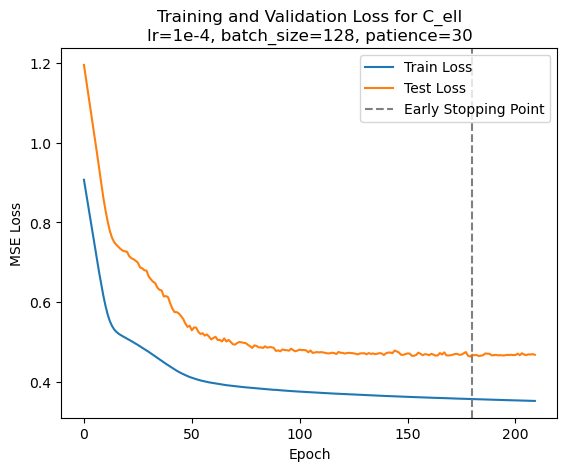

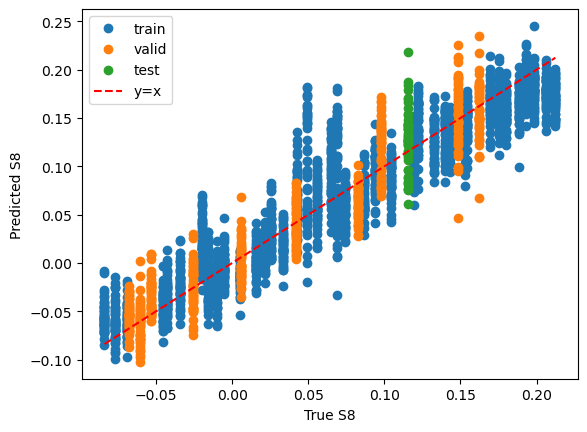

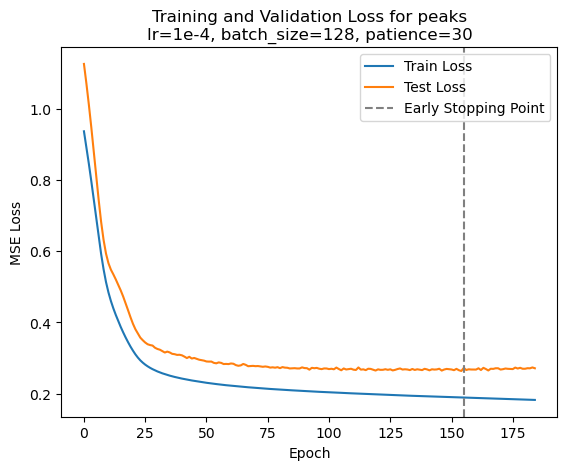

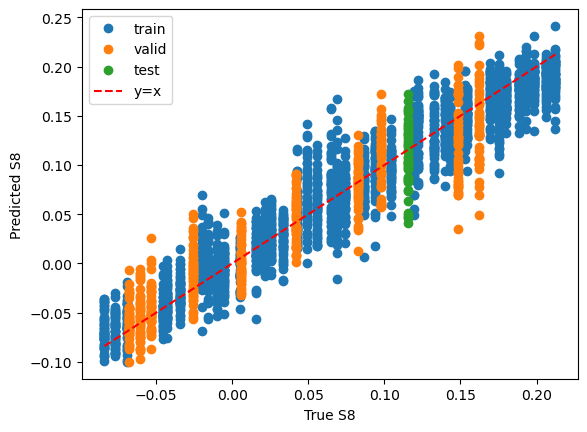

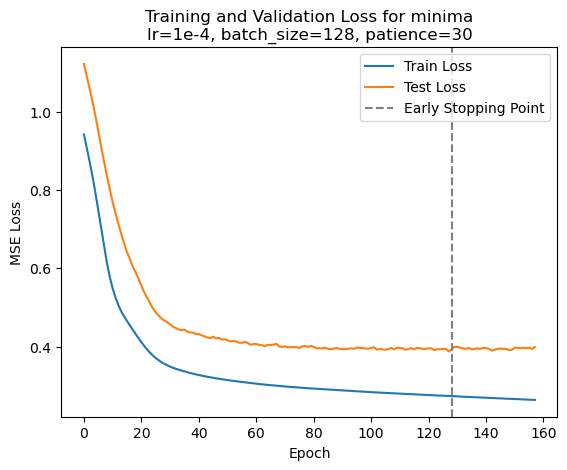

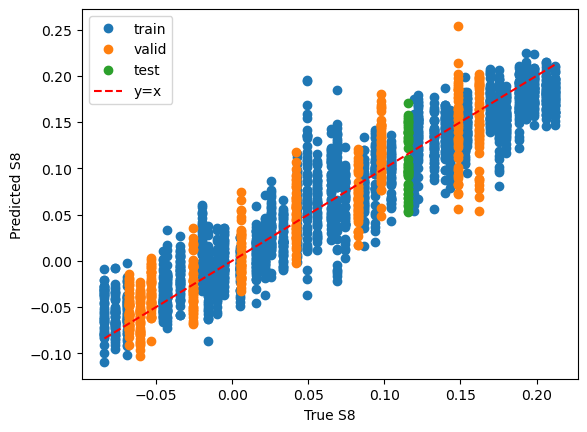

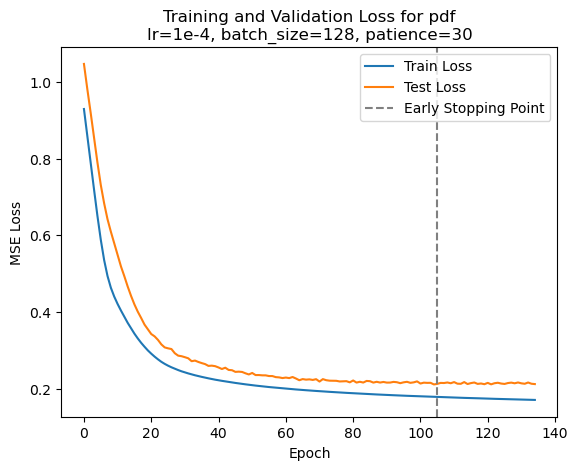

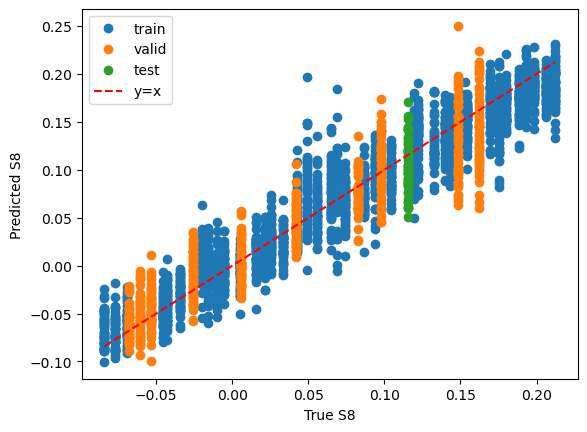

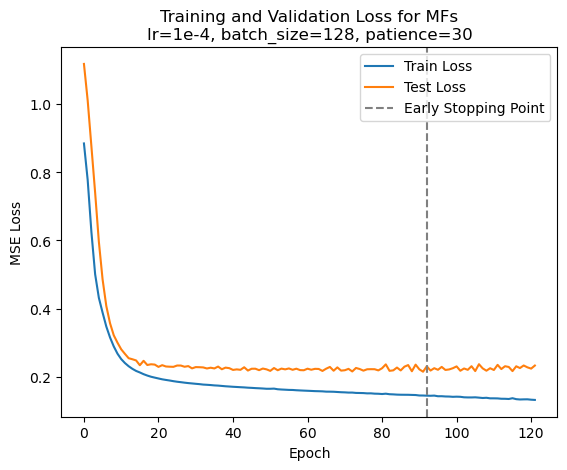

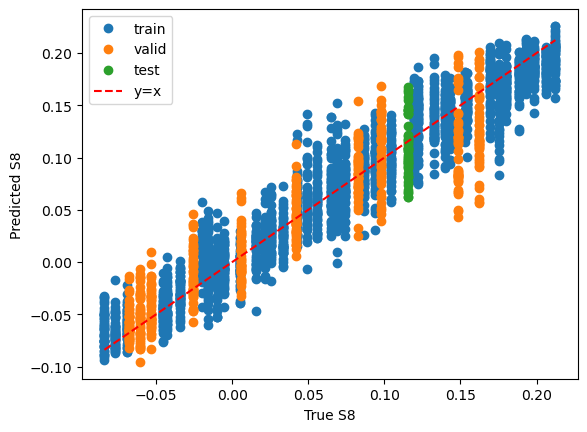

In [139]:
# Tune once on the development split. Freeze these choices for all outer LOO folds.
best_compressor_configs = {}
compressor_tuning_results = {}
theta_trained = {}
compressor_models = {}

for statistic, split in train_data.items():
    config, trials = tune_compressor(statistic, split, device)
    best_compressor_configs[statistic] = config
    compressor_tuning_results[statistic] = trials
    print(f"{statistic}: {config}")
    print("  candidates (median val MSE, seed std):", [(round(a, 4), round(b, 4)) for a, b, _ in trials])

    model, history, metrics = train_model(
        split['x_train'], split['theta_train'], split['x_valid'],
        split['theta_valid'], device, config, seed=1234,
    )
    compressor_models[statistic] = model
    pred_train = predict_cpu(model, split['x_train'], device)
    pred_valid = predict_cpu(model, split['x_valid'], device)
    pred_test = predict_cpu(model, split['x_test'], device)
    theta_trained[statistic] = (pred_train, pred_valid, pred_test)

    plt.figure(figsize=(6, 4))
    plt.plot(history['train'], label='train SmoothL1')
    plt.plot(history['valid'], label='validation MSE')
    plt.axvline(metrics['best_epoch'], color='grey', ls='--', label='selected epoch')
    plt.yscale('log')
    plt.title(f"{statistic} compressor")
    plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.show()

    # Report in normalized parameter space, avoiding the old denormalization bug.
    for name, truth, pred in [('train', split['theta_train'], pred_train),
                              ('valid', split['theta_valid'], pred_valid)]:
        mse = nn.functional.mse_loss(pred, truth).item()
        print(f"  {name} MSE={mse:.4f}")


# step 2: SBI

In [140]:
from sbi.inference import SNPE
from sbi.utils import BoxUniform

# posterior_nn location differs slightly between sbi versions
try:
    from sbi.neural_nets import posterior_nn
except ImportError:
    from sbi.utils.get_nn_models import posterior_nn

/var/tmp/pbs.605367.idark/ipykernel_244386/1760096567.py:1: FutureWarning: `sbi.inference.SNPE` is deprecated since sbi v0.27.0 and will be removed in v0.28.0. Use `sbi.inference.NPE_C` instead.
  from sbi.inference import SNPE


In [141]:
theta_train_normalized = train_data['C_ell']['theta_train']
theta_valid_normalized = train_data['C_ell']['theta_valid']
theta_test_normalized = train_data['C_ell']['theta_test']
theta_mean = train_data['C_ell']['theta_mean']
theta_std = train_data['C_ell']['theta_std']

theta_train = (theta_train_normalized * theta_std + theta_mean).to(dtype=torch.float32)
theta_valid = (theta_valid_normalized * theta_std + theta_mean).to(dtype=torch.float32)
theta_train = torch.concat([theta_train, theta_valid], dim=0)

theta_test = (theta_test_normalized * theta_std + theta_mean).to(dtype=torch.float32)



pred_train_concat = []
pred_valid_concat = []
pred_test_concat = []
for k in theta_trained.keys():
    pred_train, pred_valid, pred_test = theta_trained[k]
    pred_train_concat.append(pred_train)
    pred_valid_concat.append(pred_valid)
    pred_test_concat.append(pred_test)

/var/tmp/pbs.605367.idark/ipykernel_244386/1017190876.py:7: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_train = (theta_train_normalized * theta_std + theta_mean).to(dtype=torch.float32)
/var/tmp/pbs.605367.idark/ipykernel_244386/1017190876.py:8: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_valid = (theta_valid_normalized * theta_std + theta_mean).to(dtype=torch.float32)
/var/tmp/pbs.605367.idark/ipykernel_244386/1017190876.py:11: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_test = (theta_test_normalized * theta_std + theta_mean).to(dtype=torch.float32)


In [142]:
pred_train_concat = torch.concat(pred_train_concat, dim=1)
pred_valid_concat = torch.concat(pred_valid_concat, dim=1)
pred_test_concat = torch.concat(pred_test_concat, dim=1)


pred_train = torch.concat([pred_train_concat, pred_valid_concat], dim=0)        # sbi does valid splitting itself.
pred_test = pred_test_concat

print(pred_train.shape, pred_test.shape)

torch.Size([2450, 10]) torch.Size([50, 10])


In [143]:
theta_all = torch.concatenate([theta_train, theta_valid, theta_test], dim=0)
prior = BoxUniform(
    low=torch.tensor([theta_all[:,0].min()-0.01, theta_all[:,1].min()-0.01], dtype=torch.float32),
    high=torch.tensor([theta_all[:,0].max()+0.01, theta_all[:,1].max()+0.01], dtype=torch.float32),
)

In [144]:
density_estimator = posterior_nn(
    model="mdn",            # maybe try different model here?
    hidden_features=32,
    num_components=5,
)

# density_estimator = posterior_nn(
#     model="maf",
#     hidden_features=32,
#     num_components=5,
# )

In [145]:
inference = SNPE(
    prior=prior,
    density_estimator=density_estimator,
    device=device,
)

inference = inference.append_simulations(
    theta_train,
    pred_train,
)

trained_density_estimator = inference.train(
    training_batch_size=128,
    learning_rate=2e-4,

    # sbi takes a fraction of x_train as its internal validation set
    validation_fraction=0.2,

    stop_after_epochs=20,
    max_num_epochs=500,

    show_train_summary=True,
)

summary = inference.summary

 Neural network successfully converged after 105 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 105
        Best validation performance: -4.0699
        -------------------------
        


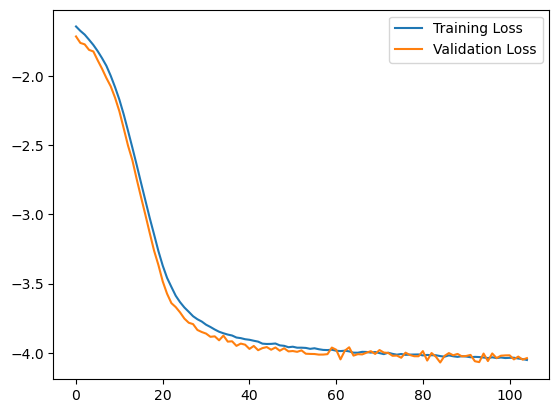

In [146]:
plt.plot(summary['training_loss'], label='Training Loss')
plt.plot(summary['validation_loss'], label='Validation Loss')
plt.legend()

In [147]:
posterior = inference.build_posterior(
    trained_density_estimator
)

In [148]:
import numpy as np
import pandas as pd

# Example: use the same bounds as your BoxUniform prior
prior_low = np.array([
    theta_train[:,0].min() - 0.01,
    theta_train[:,1].min() - 0.01,
])

prior_high = np.array([
    theta_train[:,0].max() + 0.01,
    theta_train[:,1].max() + 0.01,
])

acceptance_threshold = 0.5   # e.g. flag < 10%

low_acceptance = []

for i in range(len(pred_test)):

    samples_raw = posterior.sample(
        (20000,),
        x=pred_test[i],
        reject_outside_prior=False,
        show_progress_bars=False,
    ).cpu().detach().numpy()

    # samples_raw shape: (20000, 2)
    inside = np.all(
        (samples_raw >= prior_low) &
        (samples_raw <= prior_high),
        axis=1,
    )

    acceptance_rate = inside.mean()

    if acceptance_rate < acceptance_threshold:

        # assuming theta_test[:,0] = S8
        #          theta_test[:,1] = Om
        true_S8 = theta_test[i, 0].item()
        true_Om = theta_test[i, 1].item()

        median = np.median(samples_raw, axis=0)

        low_acceptance.append({
            "index": i,
            "S8_true": true_S8,
            "Om_true": true_Om,
            "acceptance_rate": acceptance_rate,
            "S8_raw_median": median[0],
            "Om_raw_median": median[1],
        })

        print(
            f"i={i:4d} | "
            f"accept={acceptance_rate:.4f} | "
            f"S8={true_S8:.4f}, Om={true_Om:.4f}"
        )

low_acceptance_df = pd.DataFrame(low_acceptance)

/var/tmp/pbs.605367.idark/ipykernel_244386/1086265733.py:21: UserWarning: 5.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.605367.idark/ipykernel_244386/1086265733.py:21: UserWarning: 11.8% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.605367.idark/ipykernel_244386/1086265733.py:21: UserWarning: 13.9% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.605367.idark/ipykernel_244386/1086265733.py:21: UserWarning: 49.8% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.605367.idark/ipykernel_244386/1086265733.py:21: UserWarning:

truth = [0.80186    0.14061001]
raw median = [0.82513046 0.1967298 ]
raw 16/84 = [[0.7994123  0.16746954]
 [0.84462775 0.22689582]]
raw min = [0.711066  0.0211753]
raw max = [0.8966406  0.50480044]


Text(0, 0.5, '$\\Omega_m$')

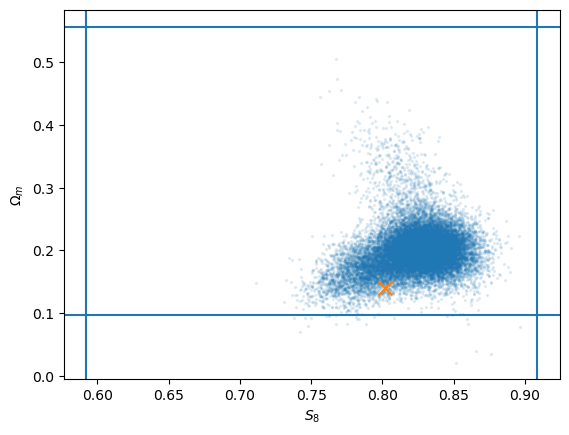

In [149]:
i = 10   # for example, one of your suspicious cases
x_obs = pred_test[i]

samples_raw = posterior.sample(
    (20000,),
    x=x_obs,
    reject_outside_prior=False,
    show_progress_bars=False,
).cpu().detach().numpy()

print("truth =", theta_test[i].numpy())

print("raw median =", np.median(samples_raw, axis=0))
print("raw 16/84 =", np.percentile(samples_raw, [16, 84], axis=0))

print("raw min =", samples_raw.min(axis=0))
print("raw max =", samples_raw.max(axis=0))

plt.scatter(
    samples_raw[:, 0],
    samples_raw[:, 1],
    s=2,
    alpha=0.1,
)

plt.axvline(prior.low[0])
plt.axvline(prior.high[0])

plt.axhline(prior.low[1])
plt.axhline(prior.high[1])

plt.scatter(
    theta_test[i, 0],
    theta_test[i, 1],
    marker="x",
    s=100,
)

plt.xlabel(r"$S_8$")
plt.ylabel(r"$\Omega_m$")

In [150]:
xx = np.linspace(0, 1, 30)
cover = [[] for _ in range(len(xx))]

for i in range(len(pred_test)):
    samples = posterior.sample(
        (5000,),
        x=pred_test[i],
        show_progress_bars=False,
    )[:, 0].cpu().numpy()

    for x, l in zip(xx, cover):
        q_low, q_high = np.quantile(samples, [(1 - x)/2, 1 - (1 - x)/2])
        truth = theta_test[i, 0].item()
        l.append(q_low <= truth <= q_high)

In [151]:
cover = np.mean(cover, axis=1)

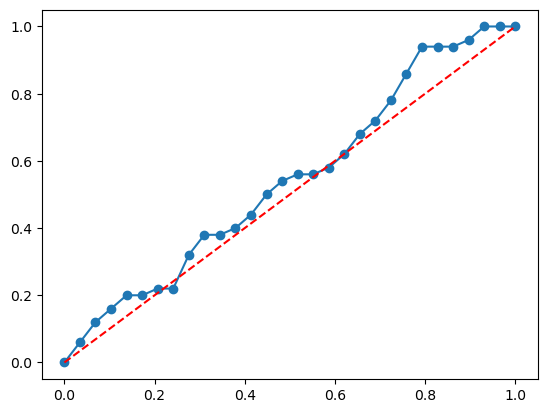

In [152]:
plt.plot(xx, cover, 'o-', label='Observed coverage')
plt.plot([0, 1], [0, 1], 'r--', label='Ideal coverage')

In [153]:
constrained_S8 = []
bias_test = []
pull_test = []
for i in range(len(pred_test)):
    x_obs = pred_test[i]

    samples = posterior.sample(
        (10000,),
        x=x_obs,
        show_progress_bars=False,
    )

    samples_np = samples[:, 0].cpu().numpy()

    q16, q50, q84 = np.percentile(samples_np, [16, 50, 84])

    true_S8 = theta_test[i, 0]

    constrained_S8.append((q16, q50, q84))

    sigma = 0.5 * (q84 - q16)
    pull = (q50 - true_S8) / sigma
    bias_test.append(q50 - true_S8)
    pull_test.append(pull)

Text(0, 0.5, 'Inferred $S_8$ with 68% CI')

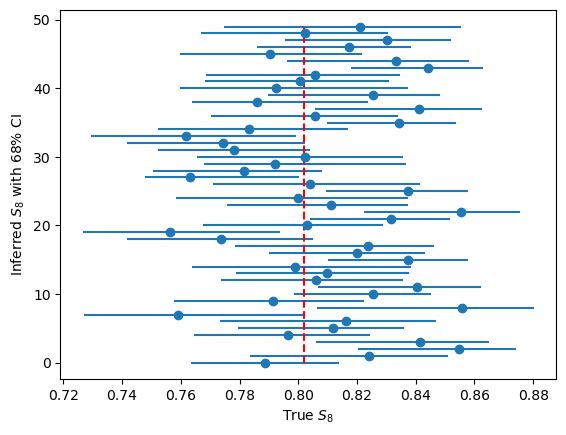

In [154]:
plt.errorbar(
    x = [q50 for q16, q50, q84 in constrained_S8],
    y = np.arange(len(constrained_S8)),
    xerr=[
        [q50 - q16 for q16, q50, q84 in constrained_S8],
        [q84 - q50 for q16, q50, q84 in constrained_S8],
    ],
    fmt='o',
)

plt.plot(
    [theta_test[i, 0].item() for i in range(len(pred_test))],
    np.arange(len(pred_test)),
    'r--',
)

plt.xlabel(r"True $S_8$")
plt.ylabel(r"Inferred $S_8$ with 68% CI")

# leave one out

In [155]:
type(posterior)

sbi.inference.posteriors.direct_posterior.DirectPosterior

In [ ]:
import os
os.makedirs(dir, exist_ok=True)

pull_all = []
bias_all = []
for leaveoutindex in range(50):

    train_data = {}

    train_data['C_ell'] = train_test_split_cosmo(C_ell_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)       # random state should be the same.
    train_data['peaks'] = train_test_split_cosmo(peak_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
    train_data['minima'] = train_test_split_cosmo(min_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
    train_data['pdf'] = train_test_split_cosmo(pdf_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
    train_data['MFs'] = train_test_split_cosmo(np.concatenate([V0_concat, V1_concat, V2_concat], axis=2), label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)

    theta_trained = {}

    for k in train_data.keys():

        # x_train, x_test, theta_train_normalized, theta_test_normalized, x_mean, x_std, theta_mean, theta_std = train_data[k]
        model, history, metrics = train_model(train_data[k]['x_train'], train_data[k]['theta_train'], train_data[k]['x_valid'], train_data[k]['theta_valid'], device, best_compressor_configs[k], seed=1000 + leaveoutindex)
        theta_mean = train_data[k]['theta_mean']
        theta_std = train_data[k]['theta_std']
        

        end_epoch = metrics['best_epoch']

        pred_train = predict_cpu(model, train_data[k]['x_train'], device)
        pred_valid = predict_cpu(model, train_data[k]['x_valid'], device)
        pred_test = predict_cpu(model, train_data[k]['x_test'], device)

        S8_train = ((train_data[k]['theta_train'][:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()
        S8_pred = ((pred_train[:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()

        S8_valid = ((train_data[k]['theta_valid'][:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()
        S8_pred = ((pred_valid[:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()


        S8_test = ((train_data[k]['theta_test'][:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()
        S8_pred = ((pred_test[:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()


        theta_trained[k] = (pred_train, pred_valid, pred_test)

    theta_train_normalized = train_data['C_ell']['theta_train']
    theta_valid_normalized = train_data['C_ell']['theta_valid']
    theta_test_normalized = train_data['C_ell']['theta_test']
    theta_mean = train_data['C_ell']['theta_mean']
    theta_std = train_data['C_ell']['theta_std']

    theta_train = (theta_train_normalized * theta_std + theta_mean).to(dtype=torch.float32)
    theta_valid = (theta_valid_normalized * theta_std + theta_mean).to(dtype=torch.float32)
    theta_train = torch.concat([theta_train, theta_valid], dim=0)

    theta_test = (theta_test_normalized * theta_std + theta_mean).to(dtype=torch.float32)



    pred_train_concat = []
    pred_valid_concat = []
    pred_test_concat = []
    for k in theta_trained.keys():
        pred_train, pred_valid, pred_test = theta_trained[k]
        pred_train_concat.append(pred_train)
        pred_valid_concat.append(pred_valid)
        pred_test_concat.append(pred_test)
    pred_train_concat = torch.concat(pred_train_concat, dim=1)
    pred_valid_concat = torch.concat(pred_valid_concat, dim=1)
    pred_test_concat = torch.concat(pred_test_concat, dim=1)


    pred_train = torch.concat([pred_train_concat, pred_valid_concat], dim=0)        # sbi does valid splitting itself.
    pred_test = pred_test_concat

    print(pred_train.shape, pred_test.shape)
    theta_all = torch.concatenate([theta_train, theta_valid, theta_test], dim=0)
    prior = BoxUniform(
        low=torch.tensor([theta_all[:,0].min()-0.01, theta_all[:,1].min()-0.01], dtype=torch.float32),
        high=torch.tensor([theta_all[:,0].max()+0.01, theta_all[:,1].max()+0.01], dtype=torch.float32),
    )


    density_estimator = posterior_nn(
        model="mdn",            # maybe try different model here?
        hidden_features=32,
        num_components=5,
    )

    inference = SNPE(
        prior=prior,
        density_estimator=density_estimator,
        device=device,
    )

    inference = inference.append_simulations(
        theta_train,
        pred_train,
    )

    trained_density_estimator = inference.train(
        training_batch_size=128,
        learning_rate=2e-4,

        # sbi takes a fraction of x_train as its internal validation set
        validation_fraction=0.2,

        stop_after_epochs=20,
        max_num_epochs=500,

        show_train_summary=True,
    )

    summary = inference.summary
    posterior = inference.build_posterior(
        trained_density_estimator
    )
    constrained_S8 = []
    bias_test = []
    pull_test = []

    xx = np.linspace(0, 1, 30)
    coverage = [[] for _ in range(len(xx))]

    for i in range(len(pred_test)):
        x_obs = pred_test[i]

        try:
            samples = posterior.sample(
                (10000,),
                x=x_obs,
                show_progress_bars=False,
                max_sampling_time=60,   # 1 minute
            )

            samples_np = samples[:, 0].cpu().numpy()

            truth = theta_test[i, 0].item()

            for x, l in zip(xx, coverage):
                q_low, q_high = np.quantile(
                    samples_np,
                    [(1 - x) / 2, 1 - (1 - x) / 2]
                )
                l.append(q_low <= truth <= q_high)

            q16, q50, q84 = np.percentile(samples_np, [16, 50, 84])

            constrained_S8.append((q16, q50, q84))

            sigma = 0.5 * (q84 - q16)
            bias_test.append(q50 - truth)
            pull_test.append((q50 - truth) / sigma)

        except RuntimeError as e:
            constrained_S8.append((np.nan, np.nan, np.nan))
            bias_test.append(np.nan)
            pull_test.append(np.nan)

            for l in coverage:
                l.append(np.nan)

            print(f"sampler failed for leaveoutindex={leaveoutindex}, i={i}: {e}")

    np.savez(f'{dir}/{leaveoutindex}_results.npz', 
        bias_test=bias_test, pull_test=pull_test, 
        true_S8 = theta_test[:,0].cpu().numpy(),
        constrained_S8=constrained_S8,
        coverage=coverage,
    )
    # pull_all.append(pull_test)
    # bias_all.append(bias_test)


/var/tmp/pbs.605367.idark/ipykernel_244386/473927798.py:52: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_train = (theta_train_normalized * theta_std + theta_mean).to(dtype=torch.float32)
/var/tmp/pbs.605367.idark/ipykernel_244386/473927798.py:53: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_valid = (theta_valid_normalized * theta_std + theta_mean).to(dtype=torch.float32)
/var/tmp/pbs.605367.idark/ipykernel_244386/473927798.py:56: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_test = (theta_test_normalized * theta_std + theta_mean).to(dtype=torch.float32)


torch.Size([2450, 10]) torch.Size([50, 10])
 Neural network successfully converged after 189 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 189
        Best validation performance: -4.0353
        -------------------------
        
torch.Size([2450, 10]) torch.Size([50, 10])
 Neural network successfully converged after 91 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 91
        Best validation performance: -3.9979
        -------------------------
        
torch.Size([2450, 10]) torch.Size([50, 10])
 Neural network successfully converged after 167 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 167
        Best validation performance: -4.0340
        -------------------------
        
torch.Size([2450, 10]) torch.Size([50, 10]